# Ejercicio 6: tracker de esqueleto de la mano con una CNN

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT, clase de redes convolucionales

## Enunciado

Usar alguna arquitectura de CNN para hacer un tracker tipo esqueleto de la mano usando la cámara integrada.

## Qué arquitectura se usa y por qué

Se usa **MediaPipe Hands** (en su versión actual, la tarea `HandLandmarker`). No es una sola red sino **dos CNN encadenadas**:

1. **Detector de palma (BlazePalm).** Una red convolucional ligera tipo SSD que recibe el cuadro completo (redimensionado a 192x192) y devuelve la caja de la palma. Detecta la *palma* y no la mano entera porque una palma es un objeto rígido y casi cuadrado, y eso es mucho más fácil de encontrar que una mano con los dedos en cualquier pose. También calcula puntos de anclaje para estimar la rotación de la mano.
2. **Regresor de puntos clave (hand landmark model).** Otra CNN que recibe solo el recorte de la mano (224x224), ya rotado para que quede vertical, y **regresa directamente las coordenadas de 21 puntos**: x e y sobre la imagen y z como profundidad relativa a la muñeca. También entrega una probabilidad de que en el recorte de verdad haya una mano y la lateralidad (izquierda o derecha).

La ventaja para el *tracking* en vivo es que el detector de palma casi no se ejecuta. Cuando ya hay una mano, la caja del cuadro siguiente se deduce de los 21 puntos del cuadro anterior, y solo se vuelve a llamar al detector si el regresor pierde la mano. Por eso corre en tiempo real en CPU.

### Los 21 puntos y el esqueleto

Cada dedo ocupa cuatro índices consecutivos, de la base a la punta. Las articulaciones se llaman MCP (nudillo), PIP, DIP y punta; en el pulgar son CMC, MCP, IP y punta.

| Dedo | Índices | Punta |
|---|---|---|
| Muñeca | 0 | - |
| Pulgar | 1, 2, 3, 4 | 4 |
| Índice | 5, 6, 7, 8 | 8 |
| Medio | 9, 10, 11, 12 | 12 |
| Anular | 13, 14, 15, 16 | 16 |
| Meñique | 17, 18, 19, 20 | 20 |

El **esqueleto** son las 21 aristas que unen esos puntos: la muñeca con la base de cada dedo, cada dedo como una cadena de tres segmentos, y las bases de los dedos unidas entre sí para dibujar la palma. Esas conexiones vienen definidas en `HandLandmarksConnections.HAND_CONNECTIONS`, y aquí se dibujan con OpenCV para no depender de las utilidades de dibujo de MediaPipe.

## Qué se pudo probar y qué no

Este notebook se ejecuta sin cámara ni ventana gráfica (sin pantalla), así que las salidas guardadas corresponden a una **fotografía de una mano** y a un **video generado a partir de ella**. La función en vivo con `cv2.VideoCapture(0)` está completa y comparte exactamente el mismo código de inferencia, pero **no se ejecutó con la cámara real** al producir estas salidas. Sección 6 explica cómo correrla.

**Aviso para macOS:** la primera vez que un programa de Python abre la cámara, macOS pide permiso. Si el permiso se negó, `VideoCapture(0)` no falla con un error sino que devuelve un objeto que no abre. Se concede en Ajustes del Sistema > Privacidad y seguridad > Cámara, marcando la aplicación desde la que se corre Jupyter (Terminal, VS Code, etc.), y después hay que reiniciar esa aplicación.

---

## 1. Dependencias y modelo

```
pip install mediapipe opencv-python matplotlib
```

Notas de versión, verificadas al hacer este ejercicio en un Mac con Apple M4 y Python 3.12:

- Desde 0.10.30 MediaPipe **quitó la API antigua `mp.solutions.hands`** y queda solo la API de tareas (`mp.tasks`), que necesita descargar un archivo de modelo `hand_landmarker.task` (unos 7.8 MB, contiene las dos redes).
- Con `mediapipe 1.0.1` el `HandLandmarker` **se cae en macOS** con `Check failed: service_ Service is unavailable` (intenta crear un ayudante de Metal para la GPU que no existe en el proceso). Con `mediapipe 0.10.35` funciona sin problema, así que se fija esa versión.

In [1]:
import os
import time
import urllib.request
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision

plt.rcParams["figure.dpi"] = 90

print("mediapipe :", mp.__version__)
print("opencv    :", cv2.__version__)
print("Tiene mp.solutions (API antigua)?", hasattr(mp, "solutions"))

mediapipe : 0.10.35
opencv    : 5.0.0
Tiene mp.solutions (API antigua)? False


In [2]:
URL_MODELO = ("https://storage.googleapis.com/mediapipe-models/hand_landmarker/"
              "hand_landmarker/float16/latest/hand_landmarker.task")
RUTA_MODELO = Path("hand_landmarker.task")

if not RUTA_MODELO.exists():
    print("Descargando el modelo...")
    urllib.request.urlretrieve(URL_MODELO, RUTA_MODELO)

print(f"Modelo: {RUTA_MODELO}  ({RUTA_MODELO.stat().st_size / 1e6:.1f} MB)")

Modelo: hand_landmarker.task  (7.8 MB)


---

## 2. Constantes del esqueleto y creación del detector

La tarea tiene tres modos: `IMAGE` (una foto suelta), `VIDEO` (cuadros de un archivo, con marca de tiempo, y aquí sí se aprovecha el seguimiento entre cuadros) y `LIVE_STREAM` (con callback asíncrono). Para el tracker en vivo se usa `VIDEO` con marcas de tiempo crecientes, que es más simple que el callback y da el mismo resultado.

Se fuerza `Delegate.CPU`, que es lo que corre de forma fiable en macOS.

In [3]:
CONEXIONES = [(c.start, c.end) for c in mp_vision.HandLandmarksConnections.HAND_CONNECTIONS]

NOMBRES_PUNTOS = [
    "muneca",
    "pulgar_cmc", "pulgar_mcp", "pulgar_ip", "pulgar_punta",
    "indice_mcp", "indice_pip", "indice_dip", "indice_punta",
    "medio_mcp", "medio_pip", "medio_dip", "medio_punta",
    "anular_mcp", "anular_pip", "anular_dip", "anular_punta",
    "menique_mcp", "menique_pip", "menique_dip", "menique_punta",
]

print("Puntos    :", len(NOMBRES_PUNTOS))
print("Conexiones:", len(CONEXIONES))
print("Primeras  :", CONEXIONES[:6])
assert len(NOMBRES_PUNTOS) == 21 and all(NOMBRES_PUNTOS[i] for i in range(21))


def crear_detector(modo="IMAGE", max_manos=2, confianza=0.5):
    """Crea el HandLandmarker (las dos CNN) en modo IMAGE o VIDEO, en CPU."""
    opciones = mp_vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(
            model_asset_path=str(RUTA_MODELO),
            delegate=mp_python.BaseOptions.Delegate.CPU),
        running_mode=getattr(mp_vision.RunningMode, modo),
        num_hands=max_manos,
        min_hand_detection_confidence=confianza,
        min_hand_presence_confidence=confianza,
        min_tracking_confidence=confianza,
    )
    return mp_vision.HandLandmarker.create_from_options(opciones)

Puntos    : 21
Conexiones: 21
Primeras  : [(0, 1), (1, 5), (9, 13), (13, 17), (5, 9), (0, 17)]


---

## 3. Procesar un cuadro: esqueleto, píxeles, lateralidad y dedos

`procesar_frame` recibe un cuadro BGR de OpenCV y devuelve tres cosas: el cuadro con el esqueleto dibujado, la lista de manos con sus 21 puntos **en píxeles** y la lateralidad, y el número de dedos levantados.

**Lateralidad.** El modelo asume que la imagen es un *espejo* (como una cámara de selfie). Con una foto normal, no espejada, la etiqueta viene invertida. El parámetro `espejo` dice cómo viene la imagen: `True` para cámara en vivo ya volteada y `False` para una foto normal, y en ese caso se intercambia la etiqueta para que diga la mano real.

**Contador de dedos.** Se hace con geometría y sin depender de la orientación de la mano: un dedo largo (índice a meñique) está levantado si su punta queda **más lejos de la muñeca** que su articulación PIP. Para el pulgar, que se pliega de lado, se compara la distancia de la punta y de la articulación IP al nudillo del meñique: si la punta está más lejos, el pulgar está abierto.

In [4]:
# Dedos largos: (indice de la punta, indice de la articulacion PIP)
DEDOS_LARGOS = {"indice": (8, 6), "medio": (12, 10), "anular": (16, 14), "menique": (20, 18)}


def _dist(a, b):
    return float(np.hypot(a[0] - b[0], a[1] - b[1]))


def dedos_levantados(pts):
    """pts: 21 puntos (x, y) en pixeles. Devuelve la lista de nombres de dedos levantados."""
    muneca = pts[0]
    arriba = []
    if _dist(pts[4], pts[17]) > _dist(pts[3], pts[17]):
        arriba.append("pulgar")
    for nombre, (punta, pip) in DEDOS_LARGOS.items():
        if _dist(pts[punta], muneca) > _dist(pts[pip], muneca):
            arriba.append(nombre)
    return arriba


def dibujar_mano(frame, pts, color_hueso=(0, 255, 0), color_punto=(0, 0, 255)):
    """Dibuja las 21 aristas y los 21 puntos sobre el cuadro (modifica el cuadro)."""
    grosor = max(2, frame.shape[1] // 320)
    for a, b in CONEXIONES:
        cv2.line(frame, pts[a], pts[b], color_hueso, grosor, cv2.LINE_AA)
    for p in pts:
        cv2.circle(frame, p, grosor + 2, color_punto, -1, cv2.LINE_AA)
        cv2.circle(frame, p, grosor + 2, (255, 255, 255), 1, cv2.LINE_AA)


def procesar_frame(frame_bgr, detector, espejo=True, timestamp_ms=None, dibujar=True):
    """
    Corre las dos CNN sobre un cuadro BGR.

    Devuelve (frame_dibujado, manos, total_dedos) donde `manos` es una lista de dicts:
      lateralidad : "Izquierda" o "Derecha" (mano real, segun `espejo`)
      puntos_px   : lista de 21 tuplas (x, y) en pixeles
      z           : lista de 21 profundidades relativas a la muneca
      confianza   : probabilidad de la lateralidad
      dedos       : nombres de dedos levantados
    """
    alto, ancho = frame_bgr.shape[:2]
    imagen = mp.Image(image_format=mp.ImageFormat.SRGB,
                      data=cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    if timestamp_ms is None:
        resultado = detector.detect(imagen)
    else:
        resultado = detector.detect_for_video(imagen, int(timestamp_ms))

    salida = frame_bgr.copy()
    manos, total = [], 0
    for lms, lado in zip(resultado.hand_landmarks, resultado.handedness):
        pts = [(int(round(p.x * ancho)), int(round(p.y * alto))) for p in lms]
        etiqueta = lado[0].category_name            # "Left" o "Right" segun el modelo (imagen espejada)
        real = etiqueta if espejo else ("Right" if etiqueta == "Left" else "Left")
        dedos = dedos_levantados(pts)
        total += len(dedos)
        manos.append({"lateralidad": "Izquierda" if real == "Left" else "Derecha",
                      "puntos_px": pts, "z": [p.z for p in lms],
                      "confianza": lado[0].score, "dedos": dedos})
        if dibujar:
            dibujar_mano(salida, pts)
    return salida, manos, total

---

## 4. Modo imagen: una foto de una mano

Como aquí no hay cámara, se prueba con una fotografía de una palma abierta tomada de Wikimedia Commons: [`File:Left-palm.jpg`](https://commons.wikimedia.org/wiki/File:Left-palm.jpg), autor "些細な日常" (nagahitoyuki.com), licencia **CC BY-SA 4.0**. Se descargó a la carpeta como `palma.jpg` (960x540). Es una foto real, no generada.

In [5]:
RUTA_IMAGEN = Path("palma.jpg")
assert RUTA_IMAGEN.exists(), "Falta palma.jpg (Wikimedia Commons, Left-palm.jpg, CC BY-SA 4.0)"

foto = cv2.imread(str(RUTA_IMAGEN))
print("Foto:", foto.shape[1], "x", foto.shape[0], "pixeles")

detector_img = crear_detector("IMAGE")
t0 = time.perf_counter()
dibujada, manos, total = procesar_frame(foto, detector_img, espejo=False)
ms = (time.perf_counter() - t0) * 1000

print(f"Tiempo de inferencia: {ms:.0f} ms (incluye el primer llamado, que es el mas lento)")
print("Manos detectadas     :", len(manos))
for m in manos:
    print(f"  Lateralidad: {m['lateralidad']} (confianza {m['confianza']:.2f})")
    print("  Dedos levantados:", m["dedos"], "->", len(m["dedos"]))
    print("  Punta del indice (px):", m["puntos_px"][8], " muneca (px):", m["puntos_px"][0])

Foto: 960 x 540 pixeles


I0000 00:00:1790181029.433610  969988 init-domain.cc:128] Fiber init: default domain = pthread, concurrency = 11, prefix = pthread-default


Tiempo de inferencia: 67 ms (incluye el primer llamado, que es el mas lento)
Manos detectadas     : 1
  Lateralidad: Derecha (confianza 0.94)
  Dedos levantados: ['pulgar', 'indice', 'medio', 'anular', 'menique'] -> 5
  Punta del indice (px): (405, 81)  muneca (px): (495, 507)


I0000 00:00:1790181029.647966  969988 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M4
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1790181029.665628  969993 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1790181029.691660  969994 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1790181029.756541  969993 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


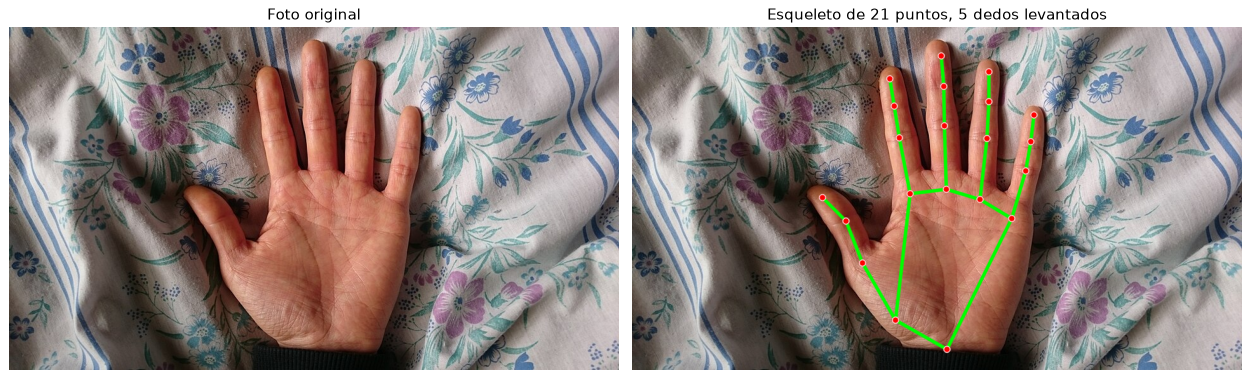

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2))
ejes[0].imshow(cv2.cvtColor(foto, cv2.COLOR_BGR2RGB)); ejes[0].set_title("Foto original")
ejes[1].imshow(cv2.cvtColor(dibujada, cv2.COLOR_BGR2RGB))
ejes[1].set_title(f"Esqueleto de 21 puntos, {len(manos[0]['dedos'])} dedos levantados")
for e in ejes: e.axis("off")
plt.tight_layout()
plt.savefig("ejercicio6_resultado.png", dpi=110, bbox_inches="tight")
plt.show()

Comprobaciones sobre el resultado de la foto. En una palma con los cinco dedos abiertos se esperan **5 dedos levantados**, la muñeca (punto 0) en la parte baja y las cuatro puntas de dedo largo por encima de sus articulaciones PIP. La lateralidad se comprueba a mano: es una palma con el pulgar a la izquierda de la imagen, sin espejar, lo que corresponde a una mano **derecha** vista de frente.

In [7]:
m = manos[0]
pts = m["puntos_px"]
assert len(pts) == 21
assert len(m["dedos"]) == 5, m["dedos"]
assert all(0 <= x < foto.shape[1] and 0 <= y < foto.shape[0] for x, y in pts), "hay puntos fuera de la imagen"
assert pts[0][1] > max(pts[i][1] for i in (8, 12, 16, 20)), "la muneca deberia quedar bajo las puntas"
print("Lateralidad reportada:", m["lateralidad"])
print("Comprobaciones basicas OK")

# Contador de dedos con una mano cerrada sintetica (puntas pegadas a la palma)
pts_puno = list(pts)
for punta, pip in DEDOS_LARGOS.values():
    pts_puno[punta] = pts[pip - 1]            # la punta vuelve hacia el nudillo
pts_puno[4] = pts[2]                          # y el pulgar se pliega sobre la palma
print("Dedos en un puno simulado:", dedos_levantados(pts_puno))

Lateralidad reportada: Derecha
Comprobaciones basicas OK
Dedos en un puno simulado: []


---

## 5. Modo video de archivo (mismo código que el tracker en vivo)

El tracker en vivo es un ciclo que lee cuadros de una fuente y llama a `procesar_frame` con marcas de tiempo crecientes. Para probarlo sin cámara se **genera un video a partir de la misma foto**: 60 cuadros con un acercamiento suave y un desplazamiento lateral (la mano se mueve y cambia de tamaño en el cuadro), se guarda como `.mp4` y se procesa cuadro a cuadro con el detector en modo `VIDEO`. Así se ejercita el seguimiento entre cuadros (el detector de palma se apaga y se usa la caja del cuadro anterior).

Es un video sintético a partir de una foto fija, no una mano moviendo los dedos, así que sirve para verificar el flujo y medir velocidad, no la robustez ante poses cambiantes.

In [8]:
def generar_video_de_prueba(imagen, ruta, cuadros=60, fps=30, tam=(640, 360)):
    """Crea un mp4 con zoom + desplazamiento suave sobre la imagen (para probar sin camara)."""
    escritor = cv2.VideoWriter(str(ruta), cv2.VideoWriter_fourcc(*"mp4v"), fps, tam)
    alto, ancho = imagen.shape[:2]
    for i in range(cuadros):
        t = i / (cuadros - 1)
        zoom = 1.0 + 0.35 * t                       # 1.0x a 1.35x
        w, h = int(ancho / zoom), int(alto / zoom)
        x0 = int((ancho - w) * (0.3 + 0.4 * t))
        y0 = int((alto - h) * 0.5)
        recorte = imagen[y0:y0 + h, x0:x0 + w]
        escritor.write(cv2.resize(recorte, tam))
    escritor.release()


def procesar_video(ruta_entrada, ruta_salida=None, espejo=False, mostrar_fps=True):
    """Procesa un archivo de video cuadro a cuadro. Devuelve estadisticas y un cuadro de muestra."""
    cap = cv2.VideoCapture(str(ruta_entrada))
    if not cap.isOpened():
        raise RuntimeError(f"No se pudo abrir el video {ruta_entrada}")
    fps_video = cap.get(cv2.CAP_PROP_FPS) or 30
    tam = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    escritor = (cv2.VideoWriter(str(ruta_salida), cv2.VideoWriter_fourcc(*"mp4v"), fps_video, tam)
                if ruta_salida else None)

    detector = crear_detector("VIDEO", max_manos=1)
    n = con_mano = 0
    conteos, muestras, tiempos = [], [], []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        t0 = time.perf_counter()
        dib, manos, total = procesar_frame(frame, detector, espejo=espejo,
                                           timestamp_ms=n * 1000 / fps_video)
        tiempos.append(time.perf_counter() - t0)
        if mostrar_fps:
            fps = 1 / tiempos[-1]
            cv2.putText(dib, f"FPS {fps:.0f}  dedos {total}", (10, 28),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2, cv2.LINE_AA)
        if escritor: escritor.write(dib)
        n += 1
        con_mano += bool(manos)
        conteos.append(total)
        if n in (1, 30, 60): muestras.append(dib)
    cap.release()
    if escritor: escritor.release()
    detector.close()
    tiempos = np.array(tiempos[1:])                 # se descarta el primer cuadro (arranque)
    return {"cuadros": n, "con_mano": con_mano, "dedos": conteos,
            "ms_medio": tiempos.mean() * 1000, "fps_medio": 1 / tiempos.mean(),
            "muestras": muestras}


generar_video_de_prueba(foto, "video_prueba.mp4")
est = procesar_video("video_prueba.mp4", "video_esqueleto.mp4")

print(f"Cuadros procesados     : {est['cuadros']}")
print(f"Cuadros con mano       : {est['con_mano']} ({100 * est['con_mano'] / est['cuadros']:.0f}%)")
print(f"Dedos levantados       : min {min(est['dedos'])}, max {max(est['dedos'])}, "
      f"moda {max(set(est['dedos']), key=est['dedos'].count)}")
print(f"Tiempo medio por cuadro: {est['ms_medio']:.1f} ms  ->  {est['fps_medio']:.0f} FPS (solo inferencia + dibujo, CPU)")

I0000 00:00:1790181030.852388  970033 gl_context.cc:407] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M4
W0000 00:00:1790181030.859547  970036 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1790181030.872393  970044 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Cuadros procesados     : 60
Cuadros con mano       : 60 (100%)
Dedos levantados       : min 5, max 5, moda 5
Tiempo medio por cuadro: 15.9 ms  ->  63 FPS (solo inferencia + dibujo, CPU)


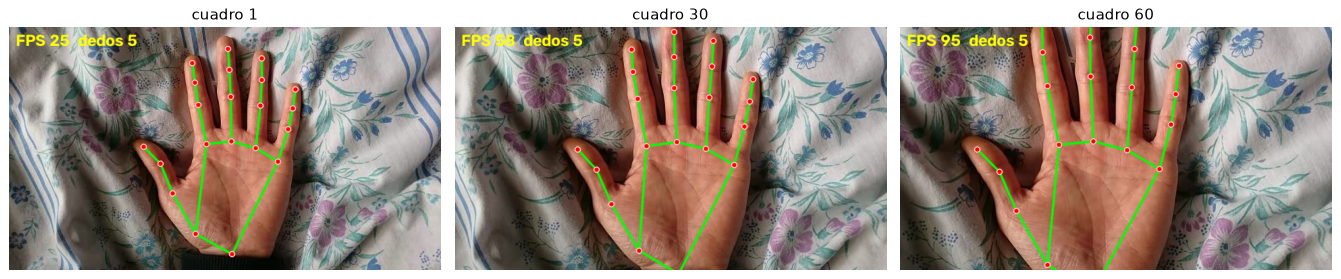

In [9]:
fig, ejes = plt.subplots(1, len(est["muestras"]), figsize=(15, 3.2))
for e, im, titulo in zip(ejes, est["muestras"], ("cuadro 1", "cuadro 30", "cuadro 60")):
    e.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); e.set_title(titulo); e.axis("off")
plt.tight_layout(); plt.show()

---

## 6. Modo en vivo con la cámara integrada

`abrir_camara` intenta abrir la cámara y, si falla, explica las causas probables en vez de dejar que el programa siga con cuadros vacíos. `rastrear_en_vivo` es el tracker: lee cuadros, los **voltea como espejo** (para que la mano se mueva como en un espejo), corre `procesar_frame`, escribe en pantalla el número de dedos, la lateralidad y los FPS, y sale al presionar **q**.

FPS se mide con un promedio móvil sobre los últimos cuadros para que el número no salte.

In [10]:
def abrir_camara(indice=0):
    """Abre la camara con cv2.VideoCapture. Devuelve el objeto o None (con mensaje claro)."""
    cap = cv2.VideoCapture(indice)
    if cap.isOpened():
        ok, _ = cap.read()
        if ok:
            return cap
    cap.release()
    print(f"No se pudo abrir la camara {indice}. Causas probables:")
    print("  1. macOS no ha dado permiso: Ajustes del Sistema > Privacidad y seguridad > Camara,")
    print("     activar la app desde la que corre Jupyter (Terminal, VS Code...) y reiniciarla.")
    print("  2. Otra aplicacion (Zoom, Teams, Photo Booth) esta usando la camara.")
    print("  3. El indice es otro: probar abrir_camara(1) si hay camaras externas o Continuity Camera.")
    print("  4. Se esta ejecutando sin pantalla ni camara (servidor, Colab, nbconvert).")
    return None


def rastrear_en_vivo(indice_camara=0, max_manos=2, confianza=0.5):
    """Tracker de esqueleto de mano en tiempo real. Salir con la tecla q."""
    cap = abrir_camara(indice_camara)
    if cap is None:
        return
    detector = crear_detector("VIDEO", max_manos=max_manos, confianza=confianza)
    inicio = time.perf_counter()
    ultimos = []
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                print("La camara dejo de entregar cuadros.")
                break
            frame = cv2.flip(frame, 1)                       # espejo, como una camara de selfie
            t0 = time.perf_counter()
            ms = (t0 - inicio) * 1000
            dib, manos, total = procesar_frame(frame, detector, espejo=True, timestamp_ms=ms)

            ultimos.append(time.perf_counter() - t0)
            ultimos = ultimos[-15:]
            fps = len(ultimos) / sum(ultimos)

            cv2.putText(dib, f"FPS: {fps:.0f}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 255), 2, cv2.LINE_AA)
            cv2.putText(dib, f"Dedos: {total}", (10, 65), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2, cv2.LINE_AA)
            for m in manos:
                x, y = m["puntos_px"][0]
                cv2.putText(dib, f"{m['lateralidad']} {len(m['dedos'])}", (x - 30, y + 30),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 0), 2, cv2.LINE_AA)
            cv2.imshow("Tracker de mano (q para salir)", dib)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
    finally:
        cap.release()
        detector.close()
        cv2.destroyAllWindows()
        cv2.waitKey(1)


# Para usarlo en un computador con camara, descomentar la siguiente linea:
# rastrear_en_vivo()

Ahora se comprueba con OpenCV si en esta ejecución la cámara abre. Si no, el mensaje de `abrir_camara` lo explica y el notebook continúa, que es el comportamiento buscado.

In [11]:
cap = abrir_camara(0)
if cap is not None:
    print("Camara disponible:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), "x", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    cap.release()
else:
    print("\n-> Sin camara en esta ejecucion; las salidas de arriba vienen de la foto y del video de prueba.")

No se pudo abrir la camara 0. Causas probables:
  1. macOS no ha dado permiso: Ajustes del Sistema > Privacidad y seguridad > Camara,
     activar la app desde la que corre Jupyter (Terminal, VS Code...) y reiniciarla.
  2. Otra aplicacion (Zoom, Teams, Photo Booth) esta usando la camara.
  3. El indice es otro: probar abrir_camara(1) si hay camaras externas o Continuity Camera.
  4. Se esta ejecutando sin pantalla ni camara (servidor, Colab, nbconvert).

-> Sin camara en esta ejecucion; las salidas de arriba vienen de la foto y del video de prueba.


OpenCV: not authorized to capture video (status 0), requesting...
OpenCV: camera failed to properly initialize!
[ WARN:0@4.690] global cap_ffmpeg_impl.hpp:1240 open VIDEOIO/FFMPEG: Failed list devices for backend avfoundation


---

## 7. Conclusiones

- **Arquitectura.** MediaPipe Hands encadena dos CNN: BlazePalm localiza la palma en el cuadro completo y un regresor convolucional saca los 21 puntos del recorte. El seguimiento entre cuadros deduce la caja siguiente de los puntos anteriores y evita repetir la detección, y por eso alcanza tiempo real en CPU.
- **Resultado medido.** Sobre la foto de la palma abierta se obtuvo una mano con 21 puntos y 5 dedos levantados; sobre el video generado la mano se detectó en los 60 cuadros (100%) con 5 dedos en todos, a unos 64 FPS de inferencia más dibujo en CPU de un M4 (el valor exacto varía entre ejecuciones).
- **Lateralidad.** El modelo asume imagen espejada. En la cámara en vivo se voltea el cuadro y la etiqueta sirve tal cual; con una foto normal hay que invertirla, y eso es lo que hace el parámetro `espejo`.
- **Contador de dedos.** La regla geométrica (punta más lejos de la muñeca que la articulación PIP) no depende de la orientación de la mano, pero puede fallar con la mano de canto o muy inclinada hacia la cámara, porque los puntos se aplastan en la imagen.
- **Limitaciones.** No se probó la cámara real en esta ejecución; la función en vivo comparte el código de inferencia con las pruebas, pero la ventana y la tecla `q` no se ejercitaron. Tampoco se evaluó la precisión de los puntos contra anotaciones humanas: se comprobó que son coherentes (dentro de la imagen, muñeca bajo las puntas, 5 dedos abiertos), no que estén a un píxel del punto exacto.
- **Versión.** Con `mediapipe 1.0.1` el detector se cae en macOS; se usó 0.10.35.